# Novae Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 03.12.2024
- Date of Last Modification: 04.12.2024 (by Sebastian Birk; sb75@sanger.ac.uk)

- Install the novae conda environment ```../../envs/novae.yaml```
- This notebook follows the tutorial from https://mics-lab.github.io/novae/tutorials/main_usage/.

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import os

import anndata as ad
import pandas as pd
import novae
import numpy as np
import scanpy as sc
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from analysis_utils import *

/lustre/scratch126/cellgen/team361/sb75/conda/envs/novae/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.2 Configure Paths

In [5]:
st_data_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/lustre/scratch126/cellgen/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

### 1.3 Define Config

In [6]:
dataset_name = 'xhs1000-39b_1p'
batches = ['batch11', 'batch19', 'batch32']
n_domains = 12
batch_key = 'sample'
niche_key = 'niche_type'

### 1.4 Run Notebook Setup

In [7]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

In [8]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/metrics', exist_ok=True)

## 2. Data

In [9]:
# Load hold out skin samples and concatenate in one adata object
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

/lustre/scratch126/cellgen/team361/sb75/conda/envs/novae/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/novae/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


/lustre/scratch126/cellgen/team361/sb75/conda/envs/novae/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


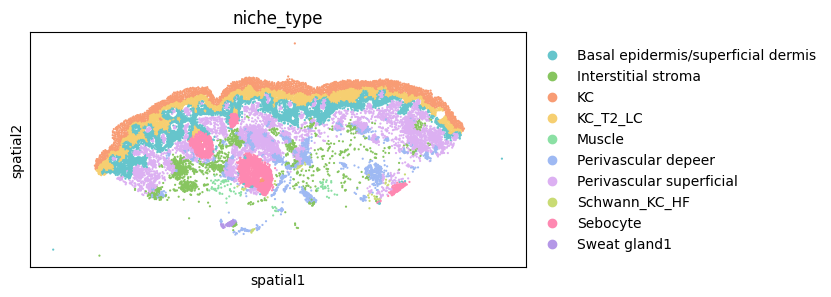

/lustre/scratch126/cellgen/team361/sb75/conda/envs/novae/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


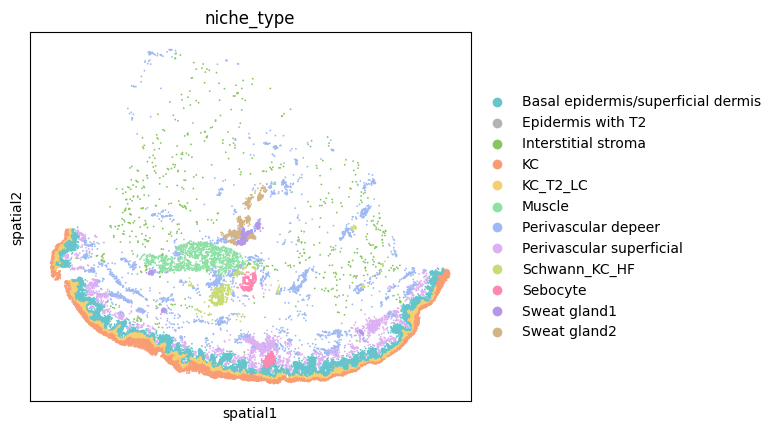

/lustre/scratch126/cellgen/team361/sb75/conda/envs/novae/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/novae/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/novae/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


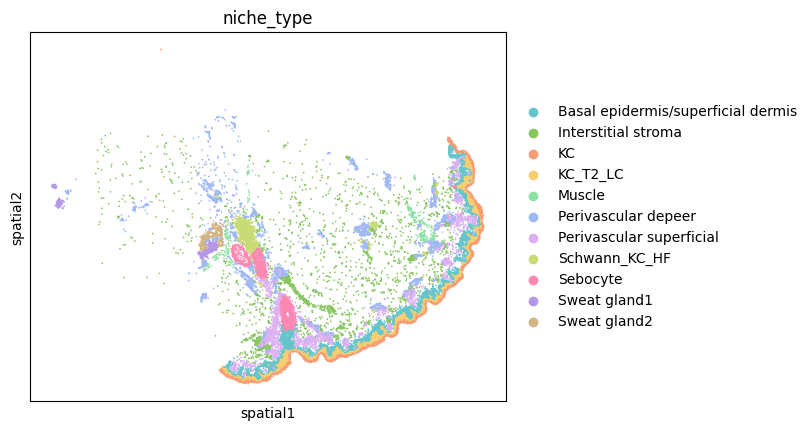

In [10]:
# Plot ground truth niches
spot_sizes = [20, 20, 20]
custom_palette_ground_truth = {niche: custom_palette[number] for niche, number in zip(
    adata.obs[niche_key].unique().tolist(), custom_palette)}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'_ground_truth_niches_{batch_id}.svg'
    sc.pl.spatial(adata_batch,
                  color=niche_key,
                  palette=custom_palette_ground_truth,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [18]:
adata_test = novae.utils.load_dataset(tissue="colon", species="human", pattern=".*P2.*")[0]
adata_test.X

[INFO] (novae.utils._data) Found 1 h5ad file(s) matching the filters.


<340837x422 sparse matrix of type '<class 'numpy.float32'>'
	with 17533937 stored elements in Compressed Sparse Row format>

## 3. Model

### 3.1 Zero-shot Niche Identification

In [12]:
model = novae.Novae.from_pretrained("MICS-Lab/novae-human-0")
model

Novae model
   ├── Known genes: 60697
   ├── Parameters: 32.0M
   └── Model name: MICS-Lab/novae-human-0

In [13]:
model.compute_representations(adata, zero_shot=True, slide_key="sample")
model.assign_domains(adata, level=n_domains)

[INFO] (novae.utils._build) Computing delaunay graph on 53,655 cells (radius threshold: [0, 100] microns)
[INFO] (novae.utils._validate) Preprocessed 1 adata object(s) with sc.pp.normalize_total and sc.pp.log1p (raw counts were saved in adata.layers['counts'])

omputing representations: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 105/105 [02:07<00:00,  1.22s/it]

'novae_domains_12'

/lustre/scratch126/cellgen/team361/sb75/conda/envs/novae/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


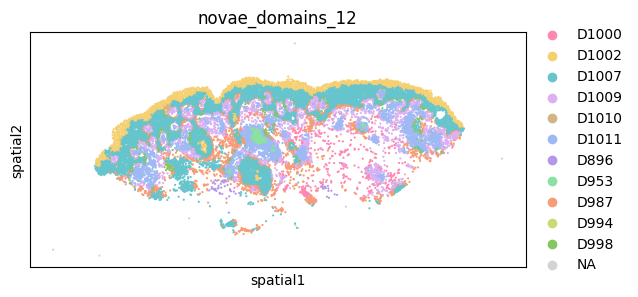

/lustre/scratch126/cellgen/team361/sb75/conda/envs/novae/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


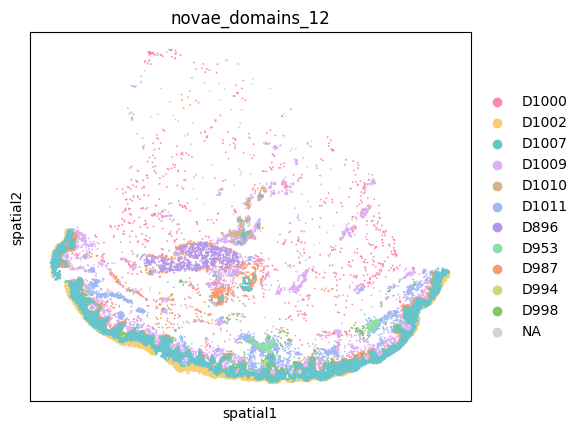

/lustre/scratch126/cellgen/team361/sb75/conda/envs/novae/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list
/lustre/scratch126/cellgen/team361/sb75/conda/envs/novae/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


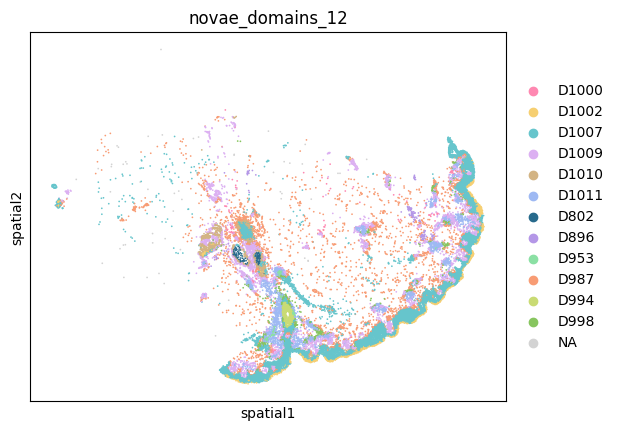

In [15]:
# Plot novae niches
# novae.plot.domains(adata, obs_key=f'novae_domains_{n_domains}')

spot_sizes = [20, 20, 20]
custom_palette_predicted = {niche: custom_palette[number] for niche, number in zip(
    adata.obs[f'novae_domains_{n_domains}'].unique().tolist(), custom_palette)}

batch_ids = adata.obs[batch_key].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs[batch_key] == batch_id]
    file_name = f'_novae_niches_{batch_id}.svg'
    sc.pl.spatial(adata_batch,
                  color=f'novae_domains_{n_domains}',
                  palette=custom_palette_predicted,
                  spot_size=spot_sizes[i],
                  save=file_name)

In [16]:
# Compute metrics
labels = adata.obs[f'niche_type']
labels_pred = adata.obs[f'novae_domains_{n_domains}']
labels_pred = np.array([-1 if x is np.nan else x for x in labels_pred])

nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)

print(f'NMI is {nmi}. ARI is {ari}.')

NMI is 0.36770626744613655. ARI is 0.20984594191187766.


In [17]:
metrics_df = pd.DataFrame({'Metric': ['NMI', 'ARI'], 'Value': [nmi, ari]})
metrics_df.to_csv(f'{benchmarking_artifacts_folder_path}/metrics/novae.csv', index=False)